In [10]:
import pandas as pd
import numpy as np

In [11]:
dataset = pd.read_csv('Dataset.csv')
dataset.sample(5)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
72,73,Female,60,50,49
33,34,Male,18,33,92
128,129,Male,59,71,11
199,200,Male,30,137,83
7,8,Female,23,18,94


In [12]:
dataset['Gender'] = dataset['Gender'].map({
    'Male': 0,
    'Female': 1
})
dataset.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,1,35,120,79
196,197,1,45,126,28
197,198,0,32,126,74
198,199,0,32,137,18
199,200,0,30,137,83


In [17]:
dataset.dtypes

CustomerID                int64
Gender                    int64
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

In [24]:
df = dataset.drop(columns='CustomerID')
df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,0,19,15,39
1,0,21,15,81
2,1,20,16,6
3,1,23,16,77
4,1,31,17,40


In [35]:
from sklearn.preprocessing import StandardScaler

nomalizer = StandardScaler()
X = df.values
new_X = nomalizer.fit_transform(X)
new_X[:5]

array([[-1.12815215, -1.42456879, -1.73899919, -0.43480148],
       [-1.12815215, -1.28103541, -1.73899919,  1.19570407],
       [ 0.88640526, -1.3528021 , -1.70082976, -1.71591298],
       [ 0.88640526, -1.13750203, -1.70082976,  1.04041783],
       [ 0.88640526, -0.56336851, -1.66266033, -0.39597992]])

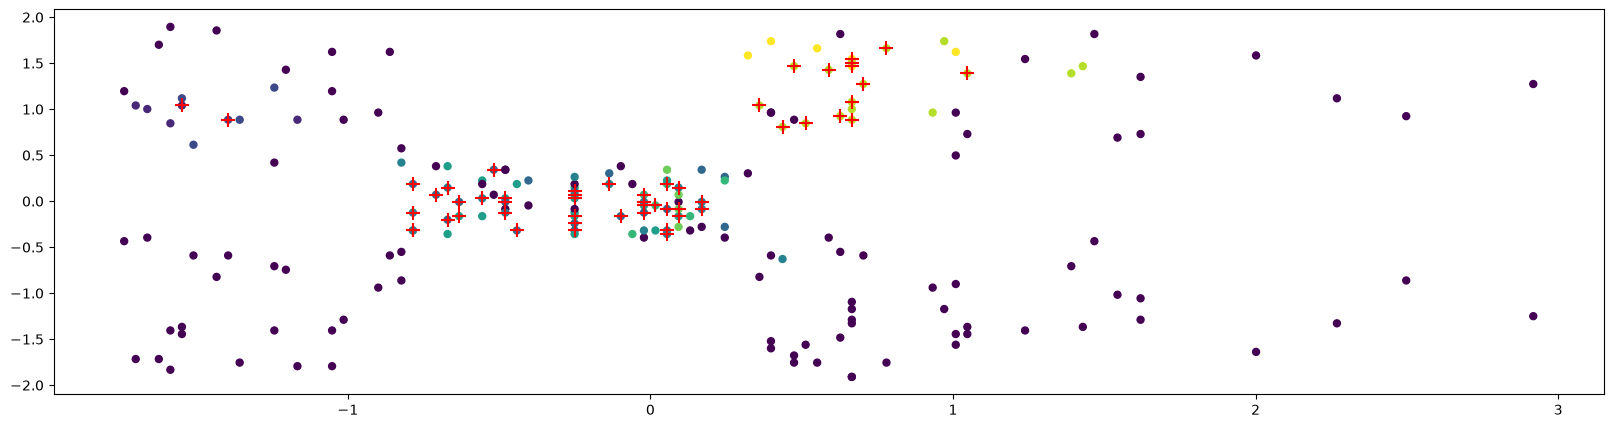

In [75]:
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt


model = DBSCAN(eps=0.5, min_samples=5)
model.fit(new_X)
fig, axs = plt.subplots(figsize=(20, 5))
axs.scatter(
    new_X[:, 2],
    new_X[:, 3],
    c=model.labels_,
    s=25
)
axs.scatter(
    new_X[model.core_sample_indices_, 2],
    new_X[model.core_sample_indices_, 3],
    c='red',
    marker='+',
    s=100
)